In [ ]:
# W4S1 live demo: a tiny network in plain NumPy (runs in Colab or locally; no GPU, no PyTorch needed)
# Run the cells top to bottom. Each cell backs one demo slide.
# %% Setup
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

In [ ]:
X, y = load_digits(return_X_y=True)
X = X / 16.0
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

def init(h, seed):
    r = np.random.default_rng(seed)
    return dict(W1=r.normal(0, 0.1, (64, h)), b1=np.zeros(h), W2=r.normal(0, 0.1, (h, 10)), b2=np.zeros(10))

def forward(p, X):
    a = np.maximum(0, X @ p['W1'] + p['b1'])
    z = a @ p['W2'] + p['b2']
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return a, e / e.sum(1, keepdims=True)

def loss_acc(p, X, y):
    _, P = forward(p, X)
    return -np.log(P[np.arange(len(y)), y] + 1e-12).mean(), (P.argmax(1) == y).mean()

def step(p, X, y, lr):
    a, P = forward(p, X)
    G = P.copy(); G[np.arange(len(y)), y] -= 1; G /= len(y)
    gW2 = a.T @ G; gb2 = G.sum(0)
    da = G @ p['W2'].T; da[a <= 0] = 0
    gW1 = X.T @ da; gb1 = da.sum(0)
    for k, g in zip(('W1', 'b1', 'W2', 'b2'), (gW1, gb1, gW2, gb2)): p[k] -= lr * g

def train(h=64, lr=0.1, steps=300, seed=0, Xt=Xtr, yt=ytr, batch=64):
    p = init(h, seed); r = np.random.default_rng(seed); tr, va = [], []
    for s in range(steps):
        i = r.choice(len(yt), min(batch, len(yt)), replace=False)
        step(p, Xt[i], yt[i], lr)
        tr.append(loss_acc(p, Xt, yt)[0]); va.append(loss_acc(p, Xva, yva)[0])
    return p, tr, va

In [ ]:
# %% Demo 1: first loss should be about ln(10) = 2.30
p = init(64, 0)
print('first loss:', round(loss_acc(p, Xtr, ytr)[0], 3), ' ln(10) =', round(np.log(10), 3))

first loss: 2.308  ln(10) = 2.303


loss on the 32 examples after 300 steps: 0.01


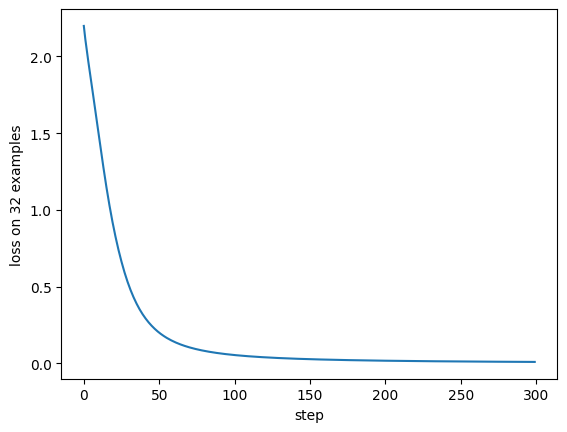

In [ ]:
# %% Demo 2: overfit ONE small batch (loss should go close to zero)
_, tr, _ = train(h=64, lr=0.3, steps=300, Xt=Xtr[:32], yt=ytr[:32], batch=32)
print('loss on the 32 examples after 300 steps:', round(tr[-1], 4))
plt.plot(tr); plt.xlabel('step'); plt.ylabel('loss on 32 examples'); plt.show()

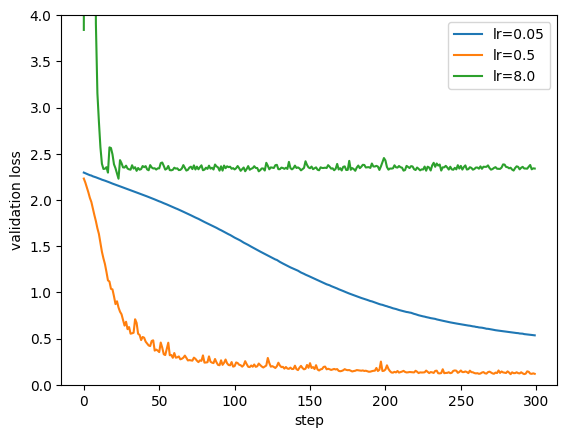

In [ ]:
# %% Demo 3: learning-rate sweep (stable, fast, too high)
for lr in (0.05, 0.5, 8.0):
    _, tr, va = train(lr=lr)
    plt.plot(va, label=f'lr={lr}')
plt.ylim(0, 4); plt.legend(); plt.xlabel('step'); plt.ylabel('validation loss'); plt.show()

In [ ]:
# %% Demo 4: is the gain bigger than the spread? Five seeds each
def acc_over_seeds(h, lr, seeds=range(5)):
    return np.array([loss_acc(train(h=h, lr=lr, seed=s)[0], Xva, yva)[1] for s in seeds])
base, new = acc_over_seeds(16, 0.1), acc_over_seeds(32, 0.1)
print('baseline h=16: %.3f +- %.3f' % (base.mean(), base.std()))
print('new      h=32: %.3f +- %.3f' % (new.mean(), new.std()))
print('gap: %.3f' % (new.mean() - base.mean()))


baseline h=16: 0.916 +- 0.012
new      h=32: 0.934 +- 0.006
gap: 0.018


# **DETAILED EXPLANATION OF THE CODE**

# Cell 1: Setup

**`# W4S1 live demo...`**  
This is just a comment telling us that we're building a small neural network using NumPy, without needing a GPU or PyTorch.

**`# Run the cells top to bottom...`**  
This reminds us to run each section in order because later sections depend on earlier ones.

**`# %% Setup`**  
This simply marks the beginning of our setup section.

**`import numpy as np`**  
First, we're importing NumPy, which helps us perform the mathematical calculations needed for our neural network.

**`import matplotlib.pyplot as plt`**  
Next, we're importing Matplotlib so we can display graphs and see how our model is learning.

**`from sklearn.datasets import load_digits`**  
This gives us a ready-made dataset of handwritten digits from 0 to 9.

**`from sklearn.model_selection import train_test_split`**  
And this helps us divide our data into training and validation sets.

# Cell 2: Building the Neural Network

**`X, y = load_digits(return_X_y=True)`**  
Here, we're loading our dataset. `X` contains the images, and `y` contains their correct digit labels.

**`X = X / 16.0`**  
We're dividing the pixel values by 16 to bring them between 0 and 1. This helps make training more stable.

**`Xtr, Xva, ytr, yva = train_test_split(...)`**  
Now we're using 70 percent of the data for training and 30 percent for validation. We're also keeping the proportion of each digit similar in both sets.

### Initializing the Network

**`def init(h, seed):`**  
Now we're defining a function to create our network. Here, `h` is the number of hidden neurons, and `seed` helps us reproduce the same random values.

**`r = np.random.default_rng(seed)`**  
This creates a random number generator that we'll use to initialize our weights.

**`return dict(W1=..., b1=..., W2=..., b2=...)`**  
Here, we're creating our weights and biases. `W1` connects 64 inputs to the hidden neurons, while `W2` connects those hidden neurons to 10 outputs, one for each digit. We're starting with random weights and zero biases.

### Forward Propagation

**`def forward(p, X):`**  
Now we're defining how information moves forward through our neural network.

**`a = np.maximum(0, X @ p['W1'] + p['b1'])`**  
We're multiplying the inputs by the weights, adding the biases, and applying ReLU. ReLU simply replaces negative values with zero.

**`z = a @ p['W2'] + p['b2']`**  
Next, we're calculating 10 output scores, one for each possible digit.

**`z = z - z.max(1, keepdims=True)`**  
We're subtracting the highest score from each row to keep our calculations numerically stable.

**`e = np.exp(z)`**  
Now we're converting those scores into exponential values.

**`return a, e / e.sum(1, keepdims=True)`**  
Finally, we're converting the scores into probabilities using softmax. All 10 probabilities for an image will add up to one.

### Calculating Loss and Accuracy

**`def loss_acc(p, X, y):`**  
This function will tell us how well our network is performing.

**`_, P = forward(p, X)`**  
First, we're getting the predicted probabilities. The underscore means we don't need the hidden-layer output here.

**`return -np.log(...).mean(), (P.argmax(1) == y).mean()`**  
Now we're calculating two things. Cross-entropy loss tells us how wrong our predictions are, while accuracy tells us how many digits we predicted correctly. The tiny number added inside the logarithm prevents numerical problems.

### Backpropagation

**`def step(p, X, y, lr):`**  
Now we're defining one training step. This is where our network learns by updating its weights.

**`a, P = forward(p, X)`**  
First, we're running forward propagation to calculate the predictions.

**`G = P.copy(); G[np.arange(len(y)), y] -= 1; G /= len(y)`**  
Here, we're calculating the gradient at the output layer. We adjust the predicted probabilities using the correct labels and divide by the number of examples.

**`gW2 = a.T @ G; gb2 = G.sum(0)`**  
Now we're calculating the gradients for the output-layer weights and biases.

**`da = G @ p['W2'].T; da[a <= 0] = 0`**  
We're passing the gradients backward through the hidden layer. ReLU blocks gradients where the hidden activation is zero.

**`gW1 = X.T @ da; gb1 = da.sum(0)`**  
Next, we're calculating the gradients for the first-layer weights and biases.

**`for k, g in zip(...): p[k] -= lr * g`**  
Finally, we're updating all the weights and biases. The learning rate controls how large each adjustment will be.

### Training the Network

**`def train(h=64, lr=0.1, steps=300, seed=0, Xt=Xtr, yt=ytr, batch=64):`**  
Now we're defining our training function. By default, we'll use 64 hidden neurons, a learning rate of 0.1, and 300 training steps.

**`p = init(h, seed); r = np.random.default_rng(seed); tr, va = [], []`**  
We're initializing the network, creating a random number generator, and preparing two lists to store training and validation losses.

**`for s in range(steps):`**  
This loop repeats the training process for the number of steps we've selected.

**`i = r.choice(len(yt), min(batch, len(yt)), replace=False)`**  
Here, we're randomly selecting a batch of training examples without repeating any example within that batch.

**`step(p, Xt[i], yt[i], lr)`**  
Now we're training the network on that batch and updating its weights.

**`tr.append(loss_acc(p, Xt, yt)[0]); va.append(loss_acc(p, Xva, yva)[0])`**  
After each step, we're recording the training and validation losses so we can see how they change.

**`return p, tr, va`**  
Finally, we're returning the trained network parameters and both loss histories.

# Cell 3: Demo 1 – Initial Loss

**`# %% Demo 1: first loss should be about ln(10) = 2.30`**  
Our first experiment checks the network's loss before training.

**`p = init(64, 0)`**  
We're creating a new network with 64 hidden neurons and a fixed random seed.

**`print('first loss:', round(loss_acc(p, Xtr, ytr)[0], 3), ' ln(10) =', round(np.log(10), 3))`**  
Now we're printing the initial loss and comparing it with 2.30. Since we have 10 possible digits, a network assigning equal probability to each digit would have a loss of about 2.30. Our randomly initialized network should start somewhere around that value.

# Cell 4: Demo 2 – Overfitting a Small Batch

**`# %% Demo 2: overfit ONE small batch`**  
Now we're checking whether our network can learn a very small set of examples.

**`_, tr, _ = train(h=64, lr=0.3, steps=300, Xt=Xtr[:32], yt=ytr[:32], batch=32)`**  
Here, we're training on just 32 images for 300 steps. We're using a learning rate of 0.3 and storing the training loss. The underscores mean we're ignoring the other returned values.

**`print('loss on the 32 examples after 300 steps:', round(tr[-1], 4))`**  
Now we're printing the final loss. We want this value to become very small, showing that the network has learned these 32 examples well.

**`plt.plot(tr); plt.xlabel('step'); plt.ylabel('loss on 32 examples'); plt.show()`**  
And here, we're plotting the training loss. If the curve moves downward toward zero, that's a good sign that our learning process is working.

# Cell 5: Demo 3 – Learning Rate

**`# %% Demo 3: learning-rate sweep`**  
Now we're checking how different learning rates affect training.

**`for lr in (0.05, 0.5, 8.0):`**  
We're going to test three learning rates: 0.05, 0.5, and 8.

**`_, tr, va = train(lr=lr)`**  
For each learning rate, we're training a new network and collecting its training and validation losses.

**`plt.plot(va, label=f'lr={lr}')`**  
Now we're plotting the validation loss for each learning rate so we can compare their performance.

**`plt.ylim(0, 4); plt.legend(); plt.xlabel('step'); plt.ylabel('validation loss'); plt.show()`**  
Finally, we're displaying the graph with labels. A smaller learning rate may learn slowly, while a very large learning rate may make training unstable. We can compare the curves to see what actually happens.

# Cell 6: Demo 4 – Comparing Model Performance

**`# %% Demo 4: is the gain bigger than the spread? Five seeds each`**  
In our final experiment, we're checking whether an improvement is consistent across multiple training runs.

**`def acc_over_seeds(h, lr, seeds=range(5)):`**  
We're defining a function that trains the network five times using different random seeds.

**`return np.array([loss_acc(train(h=h, lr=lr, seed=s)[0], Xva, yva)[1] for s in seeds])`**  
Here, we're training the network with each seed, calculating its validation accuracy, and collecting all five accuracy values.

**`base, new = acc_over_seeds(16, 0.1), acc_over_seeds(32, 0.1)`**  
Now we're comparing two networks. The baseline has 16 hidden neurons, while the new model has 32. Both use the same learning rate.

**`print('baseline h=16: %.3f +- %.3f' % (base.mean(), base.std()))`**  
We're printing the baseline model's average accuracy and standard deviation. The standard deviation tells us how much accuracy varies across runs.

**`print('new      h=32: %.3f +- %.3f' % (new.mean(), new.std()))`**  
Now we're doing the same for the larger network.

**`print('gap: %.3f' % (new.mean() - base.mean()))`**  
Finally, we're calculating the difference between their average accuracies. If the improvement is small compared with the variation across runs, we should be careful about claiming that the larger network is better.

And that's our complete demo. We've seen how a neural network makes predictions, calculates errors, updates weights, and learns from data. We've also explored how the learning rate affects training and why testing a model across multiple runs matters.